# AI Programming Foundations: Titanic Data Workflow

**Author:** Francisco Mateus

**Dataset:** Titanic: Machine Learning from Disaster (Kaggle)

This notebook builds a reproducible workflow over the 891-row Titanic passenger
table. It measures what is missing, cleans the table with four pure functions,
explores survival by sex, class, title and deck, draws five labelled figures,
and closes with a summary.

## How this notebook is organised

The headings follow the project's workflow, with Assessment and Cleaning as
separate sections:

1. **Setup**: the libraries and the versions this run used.
2. **Ingestion**: the CSV loaded from disk, with its provenance.
3. **Assessment**: what is missing, and where the gaps sit.
4. **Cleaning**: the functions that repair it, each one pure.
5. **Exploratory Analysis**: survival rates by sex, class, title and deck.
6. **Visualizations**: the labelled figures, each interpreted in the cell below it.
7. **Summary**: what the numbers support and what they do not.

Every number quoted in the written report is printed by a cell in this notebook.


## 1. Setup

I placed all the imports and the display settings in this one cell for clear organisation, and I also printed the four package versions.


In [1]:
# One import cell so no later cell can change the display settings quietly
# The version line is the reproducibility record for this run
%matplotlib inline

import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

print(f"numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")


numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Ingestion

Following the project instructions, I placed the dataset in the same folder as the notebook, 
so the notebook reads the local `titanic.csv`.
The source URL is recorded in a comment in the code cell below.


In [2]:
# Provenance: Kaggle "Titanic - Machine Learning from Disaster",
# mirror https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv
# The CSV ships beside this notebook (project Task 1)
df = pd.read_csv("titanic.csv")

df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### What the rows mean

The table below is the column dictionary: later sections check values against it.

| Column | Kind | Meaning |
|---|---|---|
| `PassengerId` | number | Row identifier; it says nothing about the person |
| `Survived` | `0` or `1` | The outcome to explain: `1` survived, `0` did not |
| `Pclass` | `1`, `2`, `3` | Ticket class: `1` first, `2` second, `3` third, there is no fourth class |
| `Name` | text | Full name; carries the honorific that the Cleaning section turns into a `title` feature |
| `Sex` | text | `male` or `female` |
| `Age` | number | Age in years; blanks are counted in the Assessment section |
| `SibSp` | number | Siblings and spouses aboard |
| `Parch` | number | Parents and children aboard |
| `Ticket` | text | Ticket number |
| `Fare` | number | Price paid for the ticket |
| `Cabin` | text | Cabin code; blank for many rows |
| `Embarked` | text | Port of boarding: `S` Southampton, `C` Cherbourg, `Q` Queenstown |


### Load check

Here I will check if the table has the following:

- `891` rows and `12` columns, the size the project expects;
- numeric columns stored as numbers, `int64` or `float64`;
- text columns stored as text, `str`.

The next cell prints each check and then asserts the shape and the dtypes, so a different file fails the run instead of producing plausible numbers.


In [3]:
# Note: Dtypes and shape asserted so a different file or an older pandas stops the run here
print(f"rows x columns: {df.shape}")
print(f"columns: {list(df.columns)}")
print(df.dtypes.to_frame("dtype").to_string())

number_columns = ["PassengerId", "Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
text_columns = ["Name", "Sex", "Ticket", "Cabin", "Embarked"]

for col in number_columns:
    assert df[col].dtype.name in {"int64", "float64"}, f"{col} stored as {df[col].dtype.name}"
for col in text_columns:
    assert df[col].dtype.name == "str", f"{col} stored as {df[col].dtype.name}"
print(f"dtype check: {len(number_columns)} numeric, {len(text_columns)} str")

assert df.shape == (891, 12), f"unexpected shape: {df.shape}"
print("load check: 891 rows, 12 columns")


rows x columns: (891, 12)
columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
               dtype
PassengerId    int64
Survived       int64
Pclass         int64
Name             str
Sex              str
Age          float64
SibSp          int64
Parch          int64
Ticket           str
Fare         float64
Cabin            str
Embarked         str
dtype check: 7 numeric, 5 str
load check: 891 rows, 12 columns


## 3. Assessment

In this section I measure the data before cleaning, and I answer four questions:

1. How many values are missing in each column?
2. Where do the gaps sit?
3. Does any row repeat another?
4. Are the values valid (plausible `Age` and `Fare` ranges, each coded
   column holding only the values the column dictionary lists)?

Each check ends in an assertion, so the run stops on a different file instead of passing silently.


### Missing values

For this check, I counted the blanks in every column, including the columns with no missing values, and printed each count beside its percentage of the `891` rows, because `2` missing values and `177` missing values are problems of different sizes.

The cell also prints the two rows whose `Embarked` is blank, the only gap small enough to check row by row. The assertions pin the three gaps this file carries.


In [4]:
# Missing-value survey of the raw table, each count beside its share of the 891 rows
missing = df.isna().sum()
pct_missing = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame(
    {"missing": missing, "pct_missing": pct_missing}
).sort_values("missing", ascending=False, kind="stable")
print(missing_report.to_string())

gapped = missing[missing > 0]
print(f"\ncolumns with gaps: {len(gapped)} -> {list(gapped.index)}")
print(f"complete columns: {len(missing) - len(gapped)}")

# The only gap small enough to inspect: one ticket, one cabin, the port missing twice
print("\nrows missing Embarked:")
print(df.loc[df["Embarked"].isna(), ["Name", "Ticket", "Fare", "Cabin"]]
      .to_string(index=False))

# Assert the three gaps this file is known to carry
assert missing["Age"] == 177, f"Age gaps: {missing['Age']}"
assert missing["Cabin"] == 687, f"Cabin gaps: {missing['Cabin']}"
assert missing["Embarked"] == 2, f"Embarked gaps: {missing['Embarked']}"
print("\ngap check: Age 177, Cabin 687, Embarked 2")


             missing  pct_missing
Cabin            687        77.10
Age              177        19.87
Embarked           2         0.22
PassengerId        0         0.00
Survived           0         0.00
Pclass             0         0.00
Name               0         0.00
Sex                0         0.00
SibSp              0         0.00
Parch              0         0.00
Ticket             0         0.00
Fare               0         0.00

columns with gaps: 3 -> ['Age', 'Cabin', 'Embarked']
complete columns: 9

rows missing Embarked:
                                     Name Ticket  Fare Cabin
                      Icard, Miss. Amelie 113572  80.0   B28
Stone, Mrs. George Nelson (Martha Evelyn) 113572  80.0   B28

gap check: Age 177, Cabin 687, Embarked 2


### Duplicates and validity

A table can be complete and still broken, so I checked three properties beyond the blanks:

- **Uniqueness**: no row is a duplicate, and every `PassengerId` is distinct.
- **Categories**: I counted every coded column and asserted it holds only the values the column dictionary lists.
- **Ranges**: I summarised `Age` and `Fare`, so the min and max are visible in the printed summary.

A fare of `0` is unusual but not impossible, so I counted those rows and kept them as they are.


In [5]:
# A table can be complete and still broken, so checks beyond the blanks
dup_rows = df.duplicated().sum()
dup_ids = df["PassengerId"].duplicated().sum()
print(f"duplicate rows: {dup_rows}")
print(f"duplicate PassengerId: {dup_ids}")

assert dup_rows == 0, "duplicate rows found"
assert df["PassengerId"].is_unique, "PassengerId repeats"
print("uniqueness check: 891 rows, 891 distinct PassengerId values")

# value_counts drops NaN, so the Embarked counts add to 889; the two blanks
# were already counted in the missing-values cell
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(f"\n{col}:")
    print(df[col].value_counts())

# Hold every coded column to the column dictionary
assert set(df["Survived"].unique()) == {0, 1}
assert set(df["Pclass"].unique()) == {1, 2, 3}
assert set(df["Sex"].unique()) == {"male", "female"}
assert set(df["Embarked"].dropna().unique()) == {"S", "C", "Q"}
print("\ncategory check: only codebook values present")

print()
# describe() counts non-empty values, so the Age count cross-checks the 177 blanks
print(df[["Age", "Fare"]].describe().round(4).to_string())

# Zero fares: counted for the record, then left as they are
zero_fare = df.loc[df["Fare"] == 0]
assert len(zero_fare) == 15, f"zero fares: {len(zero_fare)}"
print(f"\nzero fares: {len(zero_fare)}")
print(zero_fare["Pclass"].value_counts())
print("validity check: 15 zero fares, left as they are")


duplicate rows: 0
duplicate PassengerId: 0
uniqueness check: 891 rows, 891 distinct PassengerId values

Survived:
Survived
0    549
1    342
Name: count, dtype: int64

Pclass:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Sex:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked:
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

category check: only codebook values present

            Age      Fare
count  714.0000  891.0000
mean    29.6991   32.2042
std     14.5265   49.6934
min      0.4200    0.0000
25%     20.1250    7.9104
50%     28.0000   14.4542
75%     38.0000   31.0000
max     80.0000  512.3292

zero fares: 15
Pclass
2    6
1    5
3    4
Name: count, dtype: int64
validity check: 15 zero fares, left as they are


### What the assessment found

The findings below set up the cleaning section:

- `Age` is blank in `177` rows (`19.87%` of the table). That is too many to drop, so the blanks need filling.
- `Cabin` is blank in `687` rows (`77.10%`). The column is mostly absent, so the part that still carries information is the deck letter.
- `Embarked` is blank in `2` rows. Both rows share ticket `113572` and cabin `B28`, so one booking produced both gaps and one fill can fix both.
- `Fare` reaches `0` in `15` rows. They look like real records, so I left them as they are.

The other checks found nothing wrong: no duplicate rows, no repeated `PassengerId`, plausible `Age` and `Fare` ranges, and only the values the column dictionary lists.


## 4. Cleaning

In this section I repaired the three gaps the assessment found and derived two new columns, with four pure functions. A pure function copies the frame, changes the copy, and returns it, so nothing outside it changes when it runs.

`title` comes first, because the age fill reads it.

1. `title_from_name`: extracts the honorific from `Name`.
2. `fill_age`: fills the `177` blanks with the median of each title group.
3. `deck_from_cabin`: turns `Cabin` into the deck letter, `U` when unknown.
4. `fill_embarked`: fills the `2` blanks of the shared booking with `S`.


In [6]:
# Four pure functions: each copies the frame
def title_from_name(df):
    # Extract the honorific, e.g. "Mr", from `Name`
    df = df.copy()
    df["title"] = df["Name"].str.extract(r", ((?:the )?[A-Za-z]+)\.", expand=False)
    # The one peerage name ("Rothes, the Countess.") captures as "the Countess"; strip the leading "the"
    df["title"] = df["title"].str.removeprefix("the ")
    return df


def fill_age(df):
    # `Age` blanks take the median of their title group; the overall median is a fallback for a group with no known age (unused here)
    df = df.copy()
    group_median = df.groupby("title")["Age"].transform("median")
    df["Age"] = df["Age"].fillna(group_median)
    df["Age"] = df["Age"].fillna(df["Age"].median())
    return df


def deck_from_cabin(df):
    # The deck letter is the first character of `Cabin`; no record means `U`
    df = df.copy()
    df["deck"] = df["Cabin"].str[0]
    df["deck"] = df["deck"].fillna("U")
    return df


def fill_embarked(df):
    # The two blank rows are one booking (ticket `113572`); the boarding record says Southampton
    df = df.copy()
    df["Embarked"] = df["Embarked"].fillna("S")
    return df


### Applying the functions

The four functions were applied in order and then assert that every gap is closed, here it's possible to observe that: `177` age values filled, `2` ports filled, and the deck and title columns populated for all `891` rows.


In [7]:
df = title_from_name(df)

blanks_before = df["Age"].isna().sum()
group_covered = df.groupby("title")["Age"].apply(lambda s: s.notna().any())
df = fill_age(df)
df = deck_from_cabin(df)
embarked_before = df["Embarked"].isna().sum()
df = fill_embarked(df)

print(f"rows x columns: {df.shape}")
print(f"Age blanks filled: {blanks_before - df['Age'].isna().sum()}")
print(f"Embarked blanks filled: {embarked_before - df['Embarked'].isna().sum()}")
print(f"distinct titles: {df['title'].nunique()}")
print(f"rows with a cabin record: {df['Cabin'].notna().sum()}")
print(f"every title group holds at least one known age: {bool(group_covered.all())}")
print()
print("title counts:")
print(df["title"].value_counts())
print()
print("deck counts:")
print(df["deck"].value_counts().sort_index())

assert df["Age"].isna().sum() == 0, "Age blanks remain"
assert df["Embarked"].isna().sum() == 0, "Embarked blanks remain"
assert df["deck"].isna().sum() == 0, "deck blanks remain"
assert df["title"].isna().sum() == 0, "names without a title"
print("\ncleaning check: no Age, Embarked or deck blanks; every name has a title")


rows x columns: (891, 14)
Age blanks filled: 177
Embarked blanks filled: 2
distinct titles: 17
rows with a cabin record: 204
every title group holds at least one known age: True

title counts:
title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64

deck counts:
deck
A     15
B     47
C     59
D     33
E     32
F     13
G      4
T      1
U    687
Name: count, dtype: int64

cleaning check: no Age, Embarked or deck blanks; every name has a title


### What cleaning changed

- `title`: a new column with `17` distinct honorifics; `Mr` covers `517` rows, `Miss` covers `182`, `Mrs` covers `125`, and the rare ones stay as they are.
- `Age`: `177` blanks filled with their title's median; no blank survived, so the overall-median fallback filled nothing.
- `deck`: a new column; `687` passengers carry `U`, and the `204` rows with a cabin record hold the letters `A` to `G` and `T`.
- `Embarked`: the `2` blanks of the shared booking became `S`.
- Still `891` rows and nothing dropped; the zero fares stayed as they are.


## 5. Exploratory Analysis

In [8]:
# Survival rate
def rate_table(df, col):
    # nothing is assigned into df
    rows = df.groupby(col)["Survived"].agg(n="size", survived="sum")
    rows["rate"] = (rows["survived"] / rows["n"] * 100).round(2)
    return rows


survivors = df["Survived"].sum()
sex_table = rate_table(df, "Sex")
class_table = rate_table(df, "Pclass")
print(f"overall: n {len(df)}, survived {survivors}, rate {survivors / len(df) * 100:.2f}")
print()
print("by Sex:")
print(sex_table)
print()
print("by Pclass:")
print(class_table)

assert survivors == 342, f"total survivors: {survivors}"
assert sex_table.loc["female", "survived"] == 233, f"female survivors: {sex_table.loc['female', 'survived']}"
assert sex_table.loc["male", "survived"] == 109, f"male survivors: {sex_table.loc['male', 'survived']}"
assert sex_table["survived"].sum() == 342, "sex split does not cover the survivors"
assert class_table["survived"].tolist() == [136, 87, 119], f"class survivors: {class_table['survived'].tolist()}"
print("\nsurvival check: overall, sex and class splits match the pinned values")


overall: n 891, survived 342, rate 38.38

by Sex:
          n  survived   rate
Sex                         
female  314       233  74.20
male    577       109  18.89

by Pclass:
          n  survived   rate
Pclass                      
1       216       136  62.96
2       184        87  47.28
3       491       119  24.24

survival check: overall, sex and class splits match the pinned values


### The overall picture

I began with the survival rate for the full passenger list, then split it by sex, class, title, and deck. Titles held by `2` passengers or fewer went into a single `Rare` row, since a rate drawn from that small a sample is mostly noise. The underlying `title` column kept all `17` values.

`38.38` percent of the `891` passengers survived. Sex creates the widest gap. Women survived at `74.20` percent against `18.89` percent for men. Class then moves in clear steps, from `62.96` percent in first class to `47.28` in second and `24.24` in third.


In [9]:
# Survival by grouped title and by deck;
# groups with fewer than 20 passengers print last: weak evidence
SMALL_N = 20
title_counts = df["title"].value_counts()
rare_titles = title_counts[title_counts <= 2].index
title_view = df.assign(title_grouped=df["title"].mask(df["title"].isin(rare_titles), "Rare"))
title_table = rate_table(title_view, "title_grouped")
deck_table = rate_table(df, "deck")

title_main = title_table[title_table["n"] >= SMALL_N].sort_values("rate", ascending=False)
title_small = title_table[title_table["n"] < SMALL_N].sort_values("rate", ascending=False)
deck_main = deck_table[deck_table["n"] >= SMALL_N].sort_values("rate", ascending=False)
deck_small = deck_table[deck_table["n"] < SMALL_N].sort_values("rate", ascending=False)

print(f"rare titles: {len(rare_titles)} distinct, covering {title_counts[rare_titles].sum()} passengers")
print()
print("by title (grouped):")
print(pd.concat([title_main, title_small]))
print("rates for groups with fewer than 20 passengers are shown but read as weak evidence")
print()
print("by deck:")
print(pd.concat([deck_main, deck_small]))
print("rates for groups with fewer than 20 passengers are shown but read as weak evidence")
assert title_table.loc["Rare", "n"] == 14, f"Rare rows: {title_table.loc['Rare', 'n']}"
assert title_table["n"].sum() == 891 and title_table["survived"].sum() == 342, "title view does not cover the table"
assert deck_table["n"].sum() == 891 and deck_table["survived"].sum() == 342, "deck table does not cover the table"
assert df["title"].nunique() == 17, "df.title was mutated"
assert df.shape == (891, 14), "df shape changed"
print("\ntable check: Rare covers 14, both tables cover all 891 passengers and all 342 survivors")


rare titles: 11 distinct, covering 14 passengers

by title (grouped):
                 n  survived   rate
title_grouped                      
Mrs            125        99  79.20
Miss           182       127  69.78
Master          40        23  57.50
Mr             517        81  15.67
Rare            14         9  64.29
Dr               7         3  42.86
Rev              6         0   0.00
rates for groups with fewer than 20 passengers are shown but read as weak evidence

by deck:
        n  survived   rate
deck                      
D      33        25  75.76
E      32        24  75.00
B      47        35  74.47
C      59        35  59.32
U     687       206  29.99
F      13         8  61.54
G       4         2  50.00
A      15         7  46.67
T       1         0   0.00
rates for groups with fewer than 20 passengers are shown but read as weak evidence

table check: Rare covers 14, both tables cover all 891 passengers and all 342 survivors


### Titles, decks and survival

Survival broadly follows sex and life stage: adult women (`Mrs` and `Miss`, `79.20` and `69.78` percent) and boys (`Master`, `57.50`) survive at much higher rates than adult men (`Mr`, `15.67`). The figures in the next section read each split against the overall line.


## 6. Visualizations

This section turns the exploration's tables into five labelled figures, one per dimension: the overall split, then survival by sex, class, title and deck. Each figure states its question, and the cell below it reads the figure.

Every rate figure marks the overall `38.38` percent with a dashed line, so each group can be read against the baseline. In the title and deck figures, gray bars mark groups under `20` passengers, the weak-evidence rule from the exploration.


## Visualization 1: Fewer than four in ten survived

**Question:** How many of the `891` passengers survived?


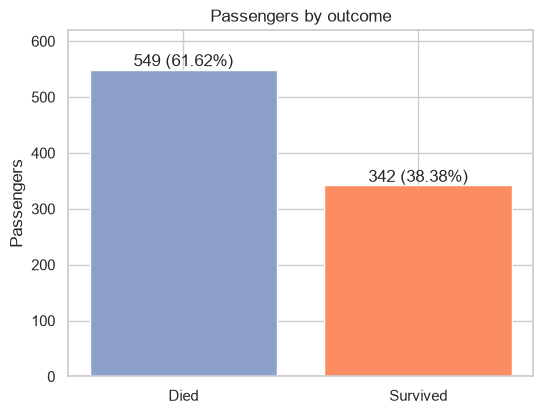

In [10]:
# Baseline: the two outcome groups
outcome = df["Survived"].value_counts().sort_index()
assert outcome.tolist() == [549, 342], f"outcome counts: {outcome.tolist()}"

palette = sns.color_palette("Set2")
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(["Died", "Survived"], outcome.values, color=[palette[2], palette[1]])
ax.bar_label(bars, labels=[f"{v} ({v / len(df) * 100:.2f}%)" for v in outcome.values])
ax.set_ylim(0, 620)
ax.set_title("Passengers by outcome")
ax.set_ylabel("Passengers")
plt.show()


The baseline: Only `342` of `891` passengers survived, `38.38` percent.<br>
Every rate figure below is read against this number.


## Visualization 2: Sex divides survival more than anything else

**Question:** How does the survival rate differ by sex?


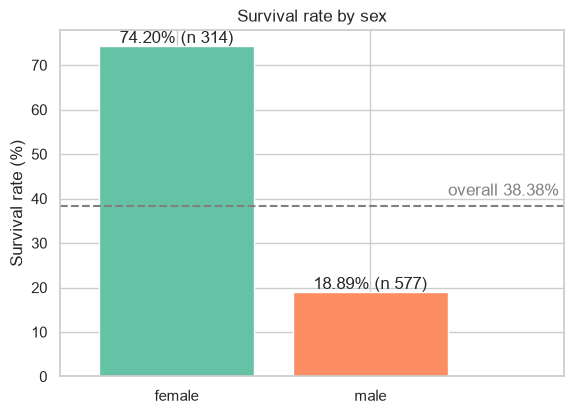

In [11]:
# Sex rates against the overall line
sex_table = rate_table(df, "Sex").loc[["female", "male"]]
assert sex_table["rate"].tolist() == [74.2, 18.89], f"sex rates: {sex_table['rate'].tolist()}"

overall = df["Survived"].mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(sex_table.index, sex_table["rate"], color=palette[:2])
ax.bar_label(bars, labels=[f"{r:.2f}% (n {n})" for r, n in zip(sex_table["rate"], sex_table["n"])])
ax.axhline(overall, color="gray", linestyle="--")
ax.text(0.99, overall + 1.5, f"overall {overall:.2f}%", transform=ax.get_yaxis_transform(), ha="right", va="bottom", color="gray")
ax.set_xlim(-0.6, 2.0)
ax.set_title("Survival rate by sex")
ax.set_ylabel("Survival rate (%)")
plt.show()


Both groups sit far from the overall line, in opposite directions. 
- Women: `74.20` percent of women survived
- Men: `18.89` percent of men survived

Note: This gap is the sharpest split in the data.


## Visualization 3: Survival falls class by class

**Question:** How does the survival rate move across the ticket classes?


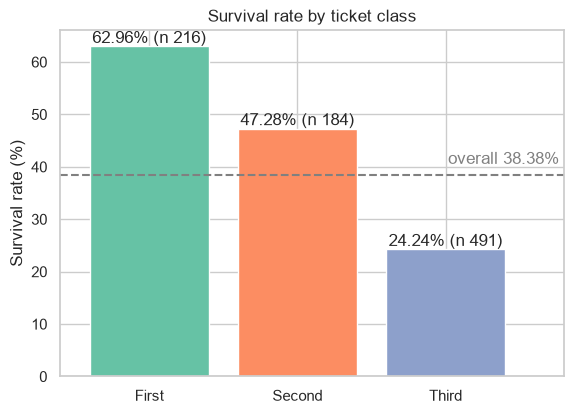

In [12]:
# Class rates in ticket order, not alphabetical
class_table = rate_table(df, "Pclass")
assert class_table["rate"].tolist() == [62.96, 47.28, 24.24], f"class rates: {class_table['rate'].tolist()}"

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["First", "Second", "Third"], class_table["rate"], color=palette[:3])
ax.bar_label(bars, labels=[f"{r:.2f}% (n {n})" for r, n in zip(class_table["rate"], class_table["n"])])
ax.axhline(overall, color="gray", linestyle="--")
ax.text(0.99, overall + 1.5, f"overall {overall:.2f}%", transform=ax.get_yaxis_transform(), ha="right", va="bottom", color="gray")
ax.set_xlim(-0.6, 2.8)
ax.set_title("Survival rate by ticket class")
ax.set_ylabel("Survival rate (%)")
plt.show()


Only first class sits above the overall line, and the rates fall in order: 
- First class: `62.96`
- Second class: `47.28`
- Third class: `24.24` percent


## Visualization 4: Title shows who the survivors were

**Question:** Who survived, by title?


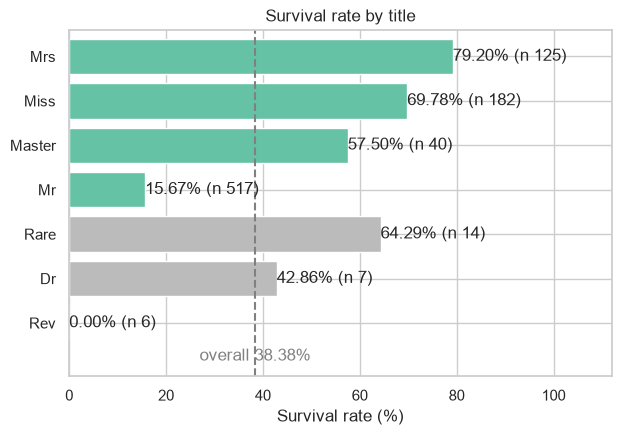

In [13]:
# Title rates, main groups first, weak-evidence groups grayed
title_counts = df["title"].value_counts()
rare_titles = title_counts[title_counts <= 2].index
title_view = df.assign(title_grouped=df["title"].mask(df["title"].isin(rare_titles), "Rare"))
title_table = rate_table(title_view, "title_grouped")
assert title_table.loc["Mrs", "rate"] == 79.2 and title_table.loc["Rare", "n"] == 14, f"title rates: {title_table['rate'].tolist()}"

title_plot = pd.concat([
    title_table[title_table["n"] >= SMALL_N].sort_values("rate", ascending=False),
    title_table[title_table["n"] < SMALL_N].sort_values("rate", ascending=False),
])
small_names = set(title_plot.index[title_plot["n"] < SMALL_N])
colors = ["#bbbbbb" if name in small_names else palette[0] for name in title_plot.index[::-1]]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.barh(title_plot.index[::-1], title_plot["rate"][::-1], color=colors)
ax.axvline(overall, color="gray", linestyle="--")
ax.bar_label(bars, labels=[f"{r:.2f}% (n {n})" for r, n in zip(title_plot["rate"][::-1], title_plot["n"][::-1])])
ax.text(overall, -0.75, f"overall {overall:.2f}%", color="gray", ha="center", va="center")
ax.set_xlim(0, 112)
ax.set_ylim(-1.2, 6.6)
ax.set_title("Survival rate by title")
ax.set_xlabel("Survival rate (%)")
plt.show()


- Far above the line: `Mrs` (`79.20`) and `Miss` (`69.78`).
- Above it, lower: `Master` (`57.50`), the children's title.
- Far below it: `Mr` (`15.67`).
- Too small to compare (gray): `Rare`, `Dr`, `Rev`.


## Visualization 5: The cabin record separates the decks

**Question:** How does survival differ by known deck?


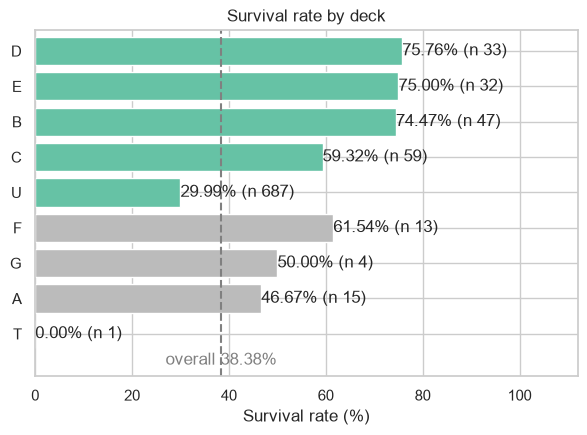

In [14]:
# Deck rates, main groups first, weak-evidence groups grayed
deck_table = rate_table(df, "deck")
assert deck_table.loc["D", "rate"] == 75.76 and deck_table.loc["U", "n"] == 687, f"deck rates: {deck_table['rate'].tolist()}"

deck_plot = pd.concat([
    deck_table[deck_table["n"] >= SMALL_N].sort_values("rate", ascending=False),
    deck_table[deck_table["n"] < SMALL_N].sort_values("rate", ascending=False),
])
small_names = set(deck_plot.index[deck_plot["n"] < SMALL_N])
colors = ["#bbbbbb" if name in small_names else palette[0] for name in deck_plot.index[::-1]]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.barh(deck_plot.index[::-1], deck_plot["rate"][::-1], color=colors)
ax.axvline(overall, color="gray", linestyle="--")
ax.bar_label(bars, labels=[f"{r:.2f}% (n {n})" for r, n in zip(deck_plot["rate"][::-1], deck_plot["n"][::-1])])
ax.text(overall, -0.75, f"overall {overall:.2f}%", color="gray", ha="center", va="center")
ax.set_xlim(0, 112)
ax.set_ylim(-1.2, 8.6)
ax.set_title("Survival rate by deck")
ax.set_xlabel("Survival rate (%)")
plt.show()


- Far above the line: `D` (`75.76`), `E` (`75.00`), `B` (`74.47`).
- Above it, lower: `C` (`59.32`).
- Below it: `U` (`29.99`), the largest group at `687` passengers.
- Too small to compare (gray): `F`, `G`, `A`, `T`.
